In [1]:
import torch
import torchvision
import torchvision.transforms as transforms

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.12.1+cu132
CUDA available: True


In [2]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100.0%
100.0%
100.0%
100.0%

Training samples: 60000
Testing samples: 10000


In [3]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("DataLoaders created!")

DataLoaders created!


In [4]:
import torch.nn as nn

class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = DigitClassifier()

print(model)

DigitClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Using device:", device)

Using device: cuda


In [6]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer ready!")

Loss function and optimizer ready!


In [7]:
epochs = 5

for epoch in range(epochs):
    model.train()

    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Make predictions
        outputs = model(images)

        # Calculate error
        loss = loss_function(outputs, labels)

        # Learn from the error
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )

Epoch 1/5, Loss: 0.3502
Epoch 2/5, Loss: 0.1590
Epoch 3/5, Loss: 0.1093
Epoch 4/5, Loss: 0.0825
Epoch 5/5, Loss: 0.0642


In [8]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 97.44%


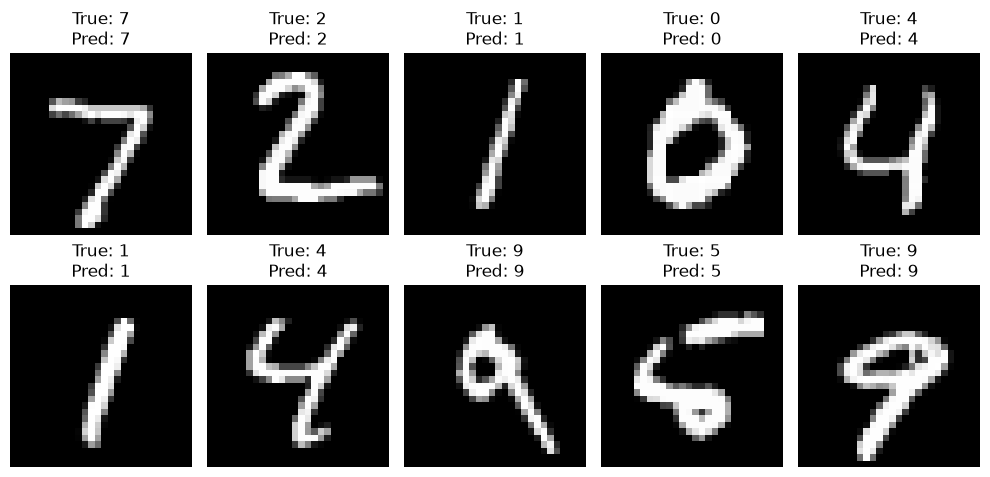

In [9]:
import matplotlib.pyplot as plt

images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].cpu().squeeze(), cmap="gray")
    ax.set_title(
        f"True: {labels[i].item()}\nPred: {predicted[i].item()}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
torch.save(model.state_dict(), "digit_classifier.pth")

print("Model saved successfully!")

Model saved successfully!
